# Modeling Using Grid Approximation

## Setup

In [1]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/usr/local/Caskroom/miniconda/base/envs/bayesian/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
obs = ['W', 'L', 'W', 'W', 'W', 'L', 'W', 'L', 'W']

### Helpers

In [3]:
def simulation_converter(simulations):
    converted_list = []
    for simulation in simulations:
        if simulation == 0:
            converted_list.append('L')
        else:
            converted_list.append("W")
    return converted_list

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def interval_display(min_boundary, max_boundary, posterior_samples):

    p = np.array(list(posterior_samples.keys()))
    posterior = np.array(list(posterior_samples.values()))

    mask = (p >= min_boundary) & (p <= max_boundary)

    interval_mass = posterior[mask].sum()

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.plot(p, posterior, label="Posterior")

    ax.fill_between(
        p, posterior, where=mask, alpha=0.3, label=f"Interval mass = {interval_mass:.4f}"
    )

    ax.axvline(min_boundary, linestyle="--", color="red")
    ax.axvline(max_boundary, linestyle="--", color="red")

    ax.set_title("Posterior Distribution")
    ax.set_xlabel("p (Probability of Water)")
    ax.set_ylabel("Posterior Probability Mass")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## Generative Model

In [5]:
def generative_model(n=10, p=0.5, size=10):
    return simulation_converter(scipy.stats.bernoulli.rvs(p, size=size))

simulations = generative_model()
print(simulations)

['L', 'L', 'L', 'L', 'W', 'L', 'L', 'W', 'L', 'W']


## Model Definition

In [6]:
def prior():
    return scipy.stats.uniform(0, 1)

def likelihood(w=6, n=9, p=None):
    return scipy.stats.binom.pmf(w, n, p)

grid = np.linspace(start=0, stop=1, num=1000)

## Model Training

### Display Priors and Posteriors

In [7]:
def grid_sampling(grid=grid):
    prior_samples = {}
    likelihood_samples = {}
    for p in grid:
        prior_samples[p] = prior().pdf(p)
        likelihood_samples[p] = likelihood(p=p)
    return prior_samples, likelihood_samples
prior_samples, likelihood_samples = grid_sampling()

In [8]:
def normalization(prior_samples, likelihood_samples):
    normalizer = 0
    for parameter in prior_samples:
        normalizer += prior_samples[parameter] * likelihood_samples[parameter]
    return normalizer


def posterior(prior_samples, likelihood_samples):
    normalizer = normalization(prior_samples, likelihood_samples)
    posterior_dict = {}
    for parameter in prior_samples:
        posterior_dict[parameter] = (
            prior_samples[parameter] * likelihood_samples[parameter]
        ) / normalizer
    return posterior_dict

posterior_samples = posterior(prior_samples, likelihood_samples)

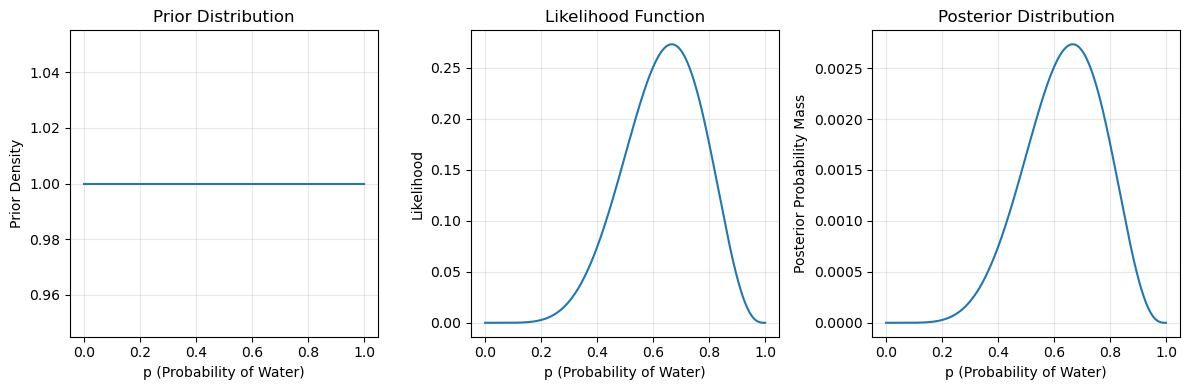

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Plot prior density
axes[0].plot(list(prior_samples.keys()), list(prior_samples.values()))
axes[0].set_title("Prior Distribution")
axes[0].set_xlabel("p (Probability of Water)")
axes[0].set_ylabel("Prior Density")
axes[0].grid(alpha=0.3)

# Plot likelihood
axes[1].plot(list(likelihood_samples.keys()), list(likelihood_samples.values()))
axes[1].set_title("Likelihood Function")
axes[1].set_xlabel("p (Probability of Water)")
axes[1].set_ylabel("Likelihood")
axes[1].grid(alpha=0.3)

# Plot posterior
axes[2].plot(list(posterior_samples.keys()), list(posterior_samples.values()))
axes[2].set_title("Posterior Distribution")
axes[2].set_xlabel("p (Probability of Water)")
axes[2].set_ylabel("Posterior Probability Mass")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Posterior Inference

In [10]:
# Posterior Mean
expectation = 0
for posterior_sample in posterior_samples.keys():
    expectation += posterior_sample * posterior_samples[posterior_sample]
expectation

np.float64(0.636363636366192)

In [11]:
# Variance

variance = 0
for posterior_sample in posterior_samples.keys():
    variance += (posterior_sample - expectation) ** 2 * posterior_samples[
        posterior_sample
    ]

variance

np.float64(0.0192837465572676)

In [12]:
# CDF

def cdf(boundary=0.5):
    accumulated_probability = 0
    for posterior_sample in posterior_samples.keys():
        if posterior_sample <= boundary:
            accumulated_probability += posterior_samples[posterior_sample]
    return accumulated_probability

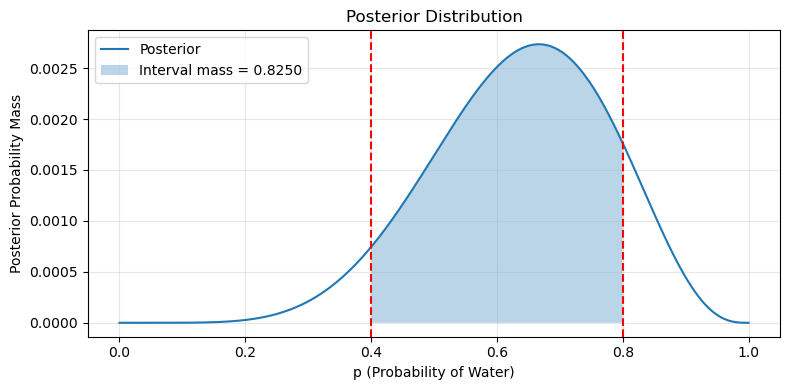

In [13]:
# Intervals of defined boundaries
min_boundary = 0.4
max_boundary = 0.8
interval_mass = cdf(max_boundary) - cdf(min_boundary)

interval_display(min_boundary, max_boundary, posterior_samples)

## Sequential Updating

In [15]:
sequential_posterior = {}
sequential_prior = prior_samples.copy()

for i, observation in enumerate(simulations):
    likelihood_samples = {}
    for p in grid:
        if observation == 'W':
            likelihood_samples[p] = p
        else:
            likelihood_samples[p] = 1 - p

    current_posterior = posterior(sequential_prior, likelihood_samples)
    sequential_posterior[i] = current_posterior
    sequential_prior = current_posterior.copy()

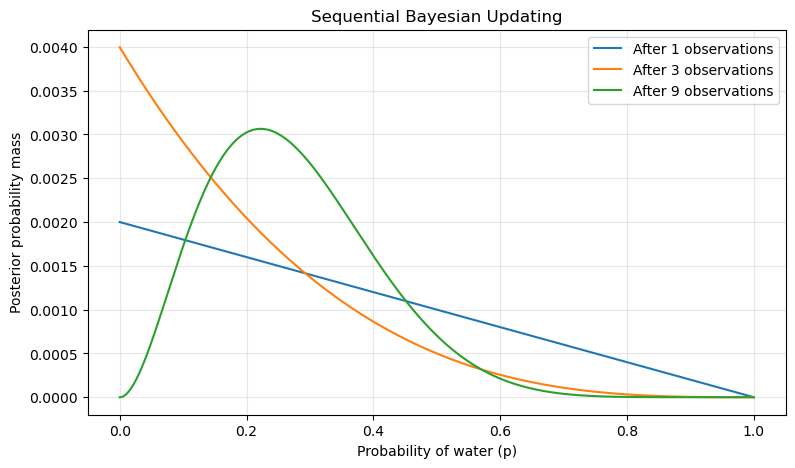

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for n in [1, 3, 9]:
    distribution = sequential_posterior[n - 1]

    plt.plot(
        list(distribution.keys()),
        list(distribution.values()),
        label=f"After {n} observations",
    )

plt.xlabel("Probability of water (p)")
plt.ylabel("Posterior probability mass")
plt.title("Sequential Bayesian Updating")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Data Generation